# ThirstMap quickstart: can AI trace water through the landscape?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yugesh1111/THIRSTMAP/blob/main/ThirstMap_quickstart.ipynb)

This notebook builds one ThirstMap scene from scratch, shows how every answer is computed and checked, lets you answer a question
and get scored by the same rules as the models, and (optionally) asks Gemini the same questions with a free key.
**About 3 minutes on a free Colab CPU. No GPU and no key needed.**

[Live demo](https://yugesh1111.github.io/THIRSTMAP/) · [Code](https://github.com/yugesh1111/THIRSTMAP) · [Findings](https://github.com/yugesh1111/THIRSTMAP/blob/main/docs/FINDINGS.md) · [Human test](https://yugesh1111.github.io/THIRSTMAP/human/)

## 1. Install
Fetches only the code (about 1 MB, not the 650 MB of published images) and installs the generator, the checks, the scorer and every pipeline stage as one `thirstmap` command.

In [1]:
![ -d thirstmap_src ] || (git clone -q --depth 1 --filter=blob:none --sparse https://github.com/yugesh1111/THIRSTMAP thirstmap_src && git -C thirstmap_src sparse-checkout set thirstmap) > /dev/null 2>&1
%pip install -q ./thirstmap_src
!thirstmap list

Note: you may need to restart the kernel to use updated packages.


usage: thirstmap <command> [options]   (thirstmap <command> --help for its options)

commands:
  generate           one scene (and its twin): images, questions, answer key
  build              a full dataset, in parallel, with manifest
  probes             reading checks (can the model read the labels?)
  variants           monsoon / haze / coarse-sensor versions of scenes
  evaluate           ask models the questions, with and without the image
  frontier           frontier check under a request budget (batched prompts)
  staircase          adaptive eye exam: breaking level per skill
  finetune           LoRA fine-tune a small open model on held-out scenes
  report             metrics, charts and REPORT.md for a results run
  findings           docs/FINDINGS.md, LEADERBOARD.md and the README findings
  overlays           model answers drawn on the images, error consequences
  human              human test page (build) and scorer (score)
  verify             independent recomputation a

## 2. Build a scene and its twin

The generator makes a landscape, **simulates where water flows** (priority-flood + D8 routing), places a data centre, its
wastewater outfall, villages and candidate wetlands, renders three image styles and writes questions whose answers come from
the simulation. Before anything is kept it **re-derives the flow with an independent library (pysheds) and checks the evidence
in the pixels** (is the path visible, is every label readable). A question that fails a check is dropped, never edited.

It also builds a **twin**: the same scene with one minimal change that must flip an answer.

In [2]:
!thirstmap build --levels 3 --per-level 1 --out ds --workers 2 > build.log 2>&1

import json
from collections import defaultdict
import matplotlib.pyplot as plt
from PIL import Image
%config InlineBackend.figure_format = "jpeg"

tasks = [json.loads(line) for line in open("ds/tasks.jsonl")]
scenes = sorted({t["scene_id"] for t in tasks})
base = next(s for s in scenes if not s.endswith("_cf"))
twin = base + "_cf" if base + "_cf" in scenes else None
key = json.load(open(f"ds/scenes/{base}/answer_key.json"))
manifest = json.load(open("ds/manifest.json"))
print(f"Built in {manifest['build_seconds']:.0f} s: scene {base}" + (f" and its twin {twin}" if twin else "") +
      f", {len(tasks)} questions (question x image style) that passed every check")

def show(paths, titles, size=5.0):
    fig, axs = plt.subplots(1, len(paths), figsize=(size * len(paths), size), dpi=80, squeeze=False)
    for ax, p, title in zip(axs[0], paths, titles):
        ax.imshow(Image.open(p)); ax.set_title(title, fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.show()

Built in 49 s: scene level3_seed38940 and its twin level3_seed38940_cf, 21 questions (question x image style) that passed every check


## 3. What the model sees
The same 4 km × 4 km scene in three styles. Each style supports different questions (only the thermal image shows water temperature).

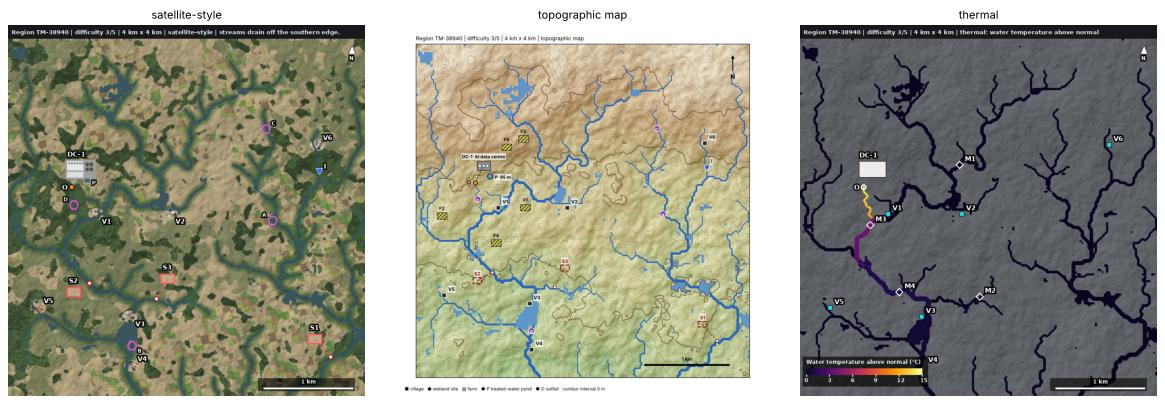

In [3]:
show([f"ds/scenes/{base}/{s}.png" for s in ("satellite", "map", "thermal")],
     ["satellite-style", "topographic map", "thermal"])

## 4. The questions, with answers computed from the simulation
*Traps* are the wrong answers a model gets if it takes a shortcut, such as naming the nearest village instead of following the flow.

In [4]:
by_q = defaultdict(list)
for t in tasks:
    if t["scene_id"] == base:
        by_q[t["qid"]].append(t)
for qid, ts in sorted(by_q.items(), key=lambda kv: int(kv[0][1:])):
    t = ts[0]
    traps = {name: labels for name, labels in t["traps"].items() if labels}
    print(f"{qid} [{t['skill']}] styles: {', '.join(x['style'] for x in ts)}")
    print(f"   {t['question']}")
    print(f"   answer: {t['answer']}" + (f"   (traps: {traps})" if traps else "") + "\n")

Q1 [trace_downstream] styles: map, satellite
   Cooling-tower wastewater from DC-1 enters the stream at outfall O. Which villages would receive this water downstream? List all.
   answer: ['V3', 'V4']   (traps: {'near_but_other_stream': ['V1']})

Q2 [order_along_flow] styles: map, satellite
   Which village would receive the wastewater first?
   answer: V3   (traps: {'near_but_other_stream': ['V1'], 'later_village': ['V4']})

Q3 [nature_based_filtering] styles: map, satellite
   A constructed wetland must clean ALL of the wastewater from O before it reaches ANY village. Which candidate site (A-D) works?
   answer: D   (traps: {'too_late_after_village': ['B']})

Q4 [read_elevation] styles: map
   Treated water is stored in pond P (spot height 95 m). Which farms can be supplied by a gravity pipe, i.e. lie LOWER than the pond? List all.
   answer: ['F1', 'F2', 'F4']

Q5 [read_flow_direction] styles: map, satellite
   In which compass direction does the stream flow just below outfall O?
  

## 5. Your turn

Look at the image, then edit `MY_ANSWER` and run the cell. You are scored by exactly the rules the models face: the exact set
for lists of labels, the right compass sector for directions, a tolerance for distances. A wrong answer is tagged with the
trap it fell into.

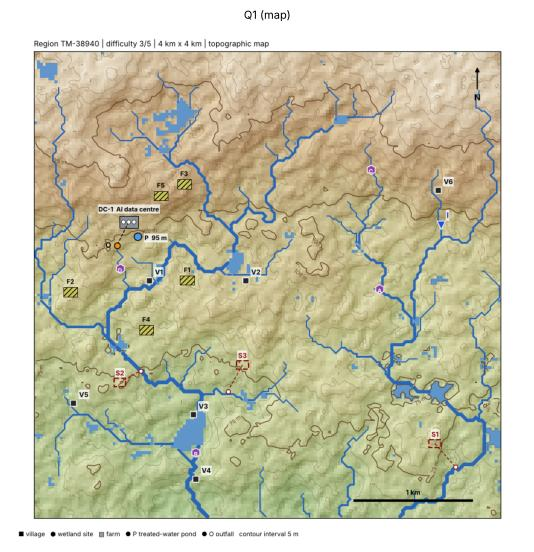

Cooling-tower wastewater from DC-1 enters the stream at outfall O. Which villages would receive this water downstream? List all.

Not quite (credit 0.0, tags ['trap:near_but_other_stream', 'missed_some']). The computed answer is ['V3', 'V4'].


In [5]:
from thirstmap.scoring import score

QID, STYLE = "Q1", "map"         # try another question from section 4
MY_ANSWER = ["V1"]               # a list of labels, a direction such as "SE", or a number

t = next((x for x in tasks if x["scene_id"] == base and x["qid"] == QID and x["style"] == STYLE),
         next(x for x in tasks if x["scene_id"] == base))
show(["ds/" + t["image"]], [f"{t['qid']} ({t['style']})"], size=7)
print(t["question"])
r = score(t, json.dumps({"answer": MY_ANSWER}))
print("\nRight!" if r["correct"] else f"\nNot quite (credit {r['credit']}, tags {r['tags']}). The computed answer is {t['answer']}.")

## 6. Check the answer yourself
Every image has a *reveal* with the true path of the water drawn on it.

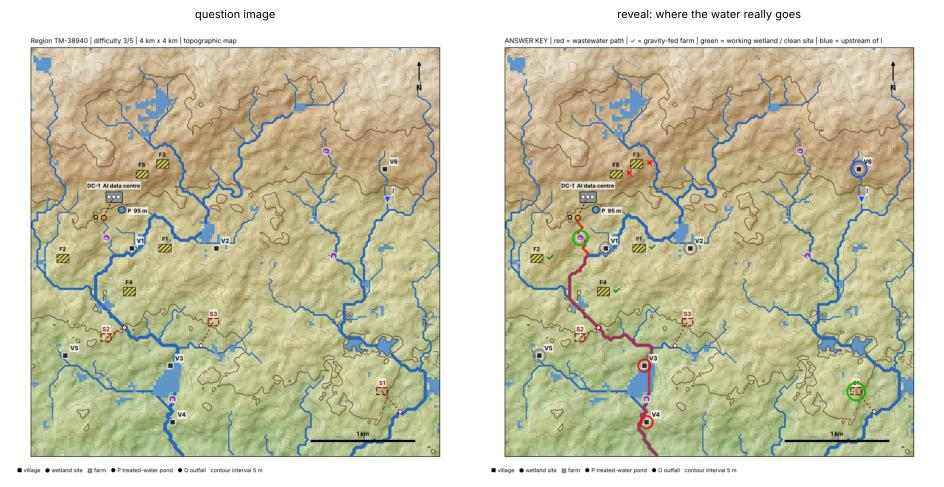

In [6]:
show(["ds/" + t["image"], "ds/" + t["reveal"]], ["question image", "reveal: where the water really goes"], size=6)

## 7. The twin: one small change that must flip the answer

A model that answers from habit (or from the question text) gives the same answer to both. Getting a before-and-after **pair**
right needs both halves right: in our runs even the best model, Gemini 3.5 Flash, managed only 6 of 19 pairs, and the others at most 2.

What changed: the wastewater pipe is rerouted: outfall O moves to a different stream


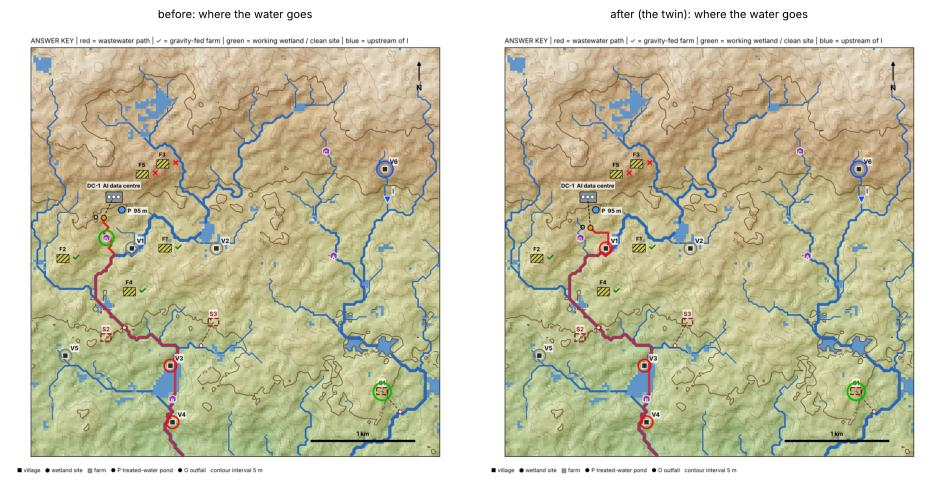

Q1: Cooling-tower wastewater from DC-1 enters the stream at outfall O. Which villages would receive this water downstream? List all.
   before: ['V3', 'V4']   after: ['V1', 'V3', 'V4']
Q2: Which village would receive the wastewater first?
   before: V3   after: V1


In [7]:
if twin:
    tkey = json.load(open(f"ds/scenes/{twin}/answer_key.json"))
    twin_tasks = [x for x in tasks if x["scene_id"] == twin]
    style = twin_tasks[0]["style"]
    print("What changed:", tkey["cf_change"])
    show([f"ds/scenes/{base}/{style}_reveal.png", f"ds/scenes/{twin}/{style}_reveal.png"],
         ["before: where the water goes", "after (the twin): where the water goes"], size=6)
    before, seen = {x["task_id"]: x for x in tasks}, set()
    for x in twin_tasks:
        if x["qid"] in seen:
            continue
        seen.add(x["qid"])
        b = before[x["pair_id"]]
        print(f"{x['qid']}: {x['question']}\n   before: {b['answer']}   after: {x['answer']}")
else:
    print("No twin passed every check for this scene.")

## 8. Run the evaluation harness (offline, no key)

`mock:oracle` answers from the key and must score 100% (a check on the scorer); `mock:random` guesses among the options (an
estimate of chance). Real models use the same command: `claude:MODEL`, `openai:MODEL@BASE_URL`, `gemini:MODEL`, or `hf:ORG/MODEL`
for any open Hugging Face vision model.

mock:oracle  21/21 correct; chance 14%; p (beats chance) = 1.3e-18
mock:random  2/21 correct; chance 14%; p (beats chance) = 0.82


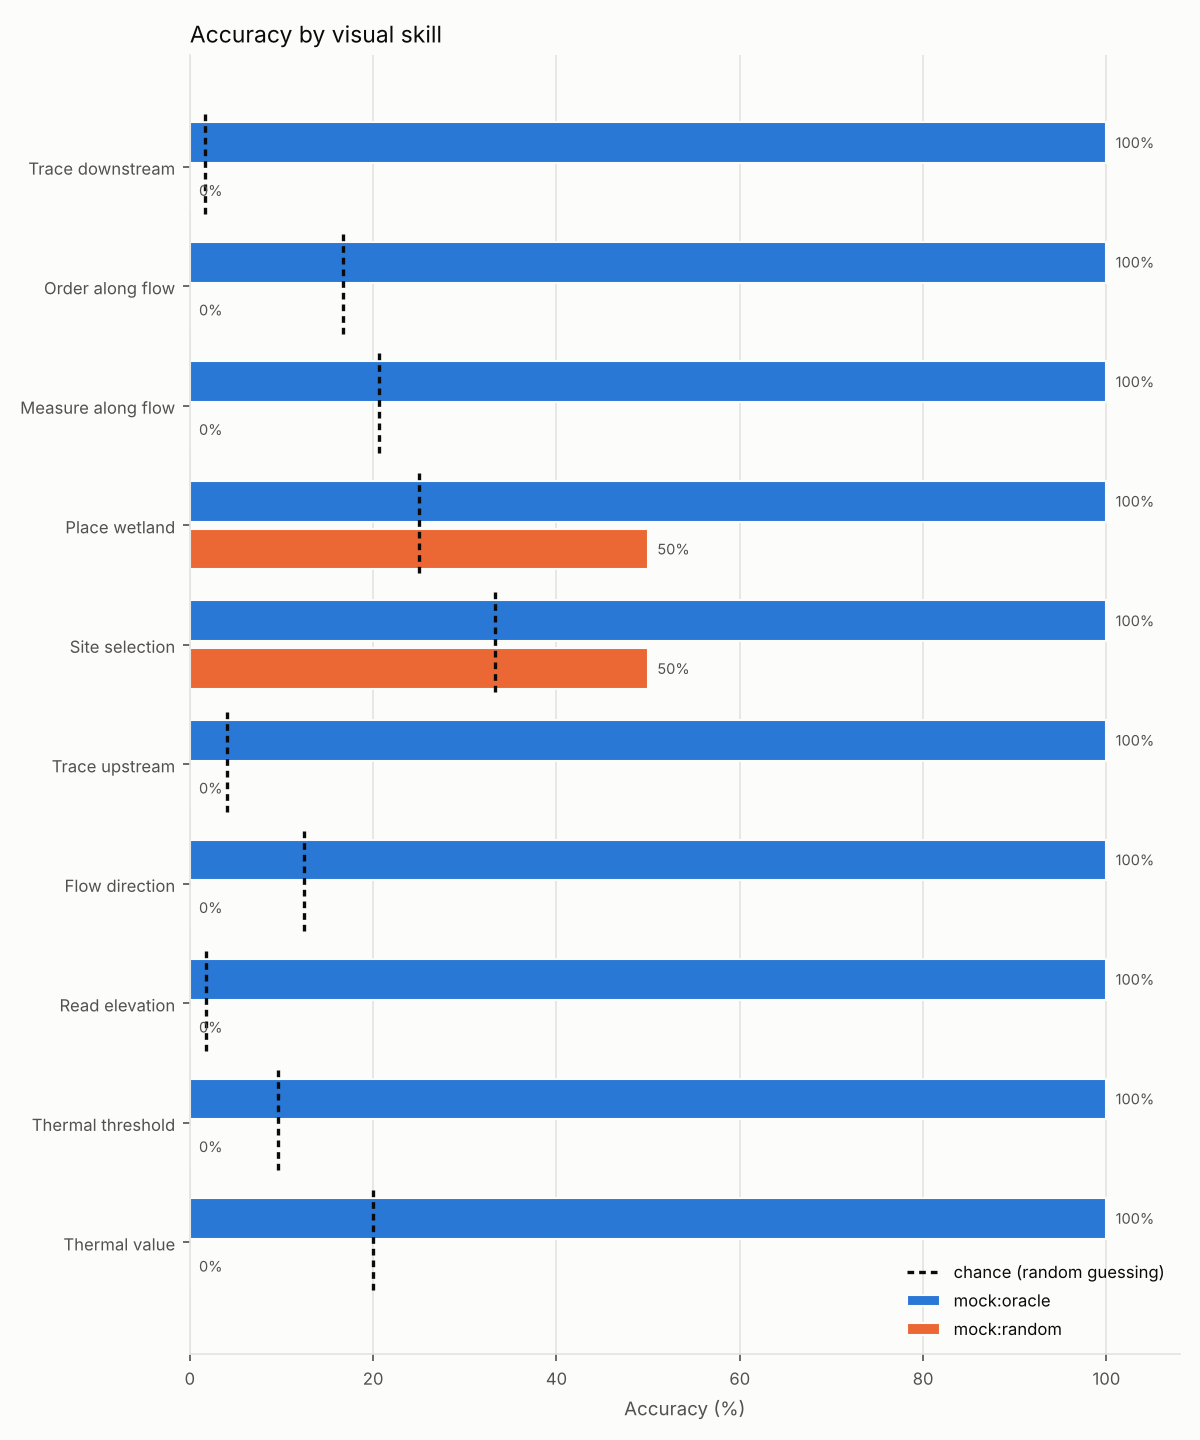

In [8]:
!thirstmap evaluate --dataset ds --models mock:oracle mock:random --run nb > /dev/null 2>&1
!thirstmap report results/nb --dataset ds > /dev/null 2>&1

summary = json.load(open("results/nb/summary.json"))
for model, v in summary["vs_chance"].items():
    print(f"{model:12s} {v['correct']}/{v['n']} correct; chance {v['chance']:.0%}; p (beats chance) = {v['p_value']:.2g}")
from IPython.display import Image as Picture, display
display(Picture("results/nb/chart_accuracy_by_skill.png", width=640))

## 9. Optional: ask Gemini (free key, 2 requests)

Get a free key at [aistudio.google.com/apikey](https://aistudio.google.com/apikey) and add it in Colab's **Secrets** panel
(the key icon on the left) as `GEMINI_API_KEY`. Every question about an image goes in one request (batch prompting), so this
uses 2 of the free tier's ~20 daily requests: the scene and its twin. Without a key the cell just skips.

In [9]:
import base64, io, os, subprocess, sys

MODEL = "gemini-3.1-flash-lite"
api_key = os.environ.get("GEMINI_API_KEY")
try:
    from google.colab import userdata
    api_key = api_key or userdata.get("GEMINI_API_KEY")
except Exception:
    pass

def png_b64(path, side=768):               # one 768 px image: the same input the published run used
    im = Image.open(path).convert("RGB")
    s = side / max(im.size)
    if s < 1:
        im = im.resize((round(im.width * s), round(im.height * s)), Image.LANCZOS)
    buf = io.BytesIO(); im.save(buf, "PNG", optimize=True)
    return base64.b64encode(buf.getvalue()).decode()

if not api_key:
    print("No GEMINI_API_KEY found, so this step is skipped. Section 10 shows the published results.")
else:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openai"], check=True)
    from openai import OpenAI
    from thirstmap.cli import tools_dir
    sys.path.insert(0, str(tools_dir()))
    from frontier import batch_prompt, parse_batch
    client = OpenAI(api_key=api_key, base_url="https://generativelanguage.googleapis.com/v1beta/openai/", max_retries=6)
    style = [x for x in tasks if x["scene_id"] == twin][0]["style"] if twin else "map"
    got = {}
    for sid in filter(None, (base, twin)):
        ts = sorted((x for x in tasks if x["scene_id"] == sid and x["style"] == style), key=lambda x: int(x["qid"][1:]))
        content = [{"type": "text", "text": batch_prompt(ts)},
                   {"type": "image_url", "image_url": {"url": "data:image/png;base64," + png_b64("ds/" + ts[0]["image"])}}]
        try:
            reply = client.chat.completions.create(model=MODEL, messages=[{"role": "user", "content": content}])
        except Exception as e:      # 429: the free daily quota is used up; 503: the service is busy
            print(f"\n{sid}: no answer ({type(e).__name__}: {str(e)[:120]}). Try again later or set MODEL to another model.")
            continue
        answers = parse_batch(reply.choices[0].message.content or "")
        print(f"\n{sid} ({style}):")
        for x in ts:
            r = score(x, json.dumps({"answer": answers.get(x["qid"])}))
            got[x["task_id"]] = r["correct"]
            print(f"  {x['qid']}: {'right' if r['correct'] else 'WRONG'}   model {r['parsed']}   computed {x['answer']}")
    pairs = [x for x in tasks if x["scene_id"] == twin and x["task_id"] in got and x["pair_id"] in got]
    if pairs:
        print("\nBefore-and-after pairs (both halves must be right):")
    for x in pairs:
        print(f"  {x['qid']}: {'both right' if got[x['pair_id']] and got[x['task_id']] else 'missed'}"
              f"   (scene {'right' if got[x['pair_id']] else 'wrong'}, twin {'right' if got[x['task_id']] else 'wrong'})")


level3_seed38940 (map):
  Q1: WRONG   model ['V1', 'V3', 'V4']   computed ['V3', 'V4']
  Q2: WRONG   model V1   computed V3
  Q3: right   model D   computed D
  Q4: WRONG   model ['F1', 'F2', 'F3', 'F4', 'F5']   computed ['F1', 'F2', 'F4']
  Q5: WRONG   model SE   computed S
  Q6: WRONG   model S3   computed S1
  Q7: right   model ['V6']   computed ['V6']
  Q10: WRONG   model 600.0   computed 2060



level3_seed38940_cf (map):
  Q1: right   model ['V1', 'V3', 'V4']   computed ['V1', 'V3', 'V4']
  Q2: right   model V1   computed V1

Before-and-after pairs (both halves must be right):
  Q1: missed   (scene wrong, twin right)
  Q2: missed   (scene wrong, twin right)


## 10. Published results
Read live from the repository, so this is always the current leaderboard.

# ThirstMap leaderboard

Generated by `findings.py` from the result files; every number links back to raw replies in `results/`. Chance = expected score of random guessing on the same questions. *Pairs* = before-and-after pairs answered right on both sides.

## Frontier check (same questions for every model, batched)

18 images, 6 before-and-after pairs; every question about an image in one request (`frontier.py`).

| # | Model | Kind | Correct | Chance | p (beats chance) | Pairs right |
|---|---|---|---|---|---|---|
| 1 | gemini-3.1-flash-lite | API | **48%** (40/83) | 14% | 1.2e-13 | 0% of 7 |
| 2 | gemini-3.5-flash-lite | API | **40%** (33/83) | 14% | 7.6e-09 | 0% of 7 |
| 3 | Qwen2.5-VL-3B-Instruct | open, local | **12%** (10/83) | 14% | 0.75 | 0% of 7 |
| 4 | Qwen2-VL-2B-Instruct | open, local | **5%** (4/83) | 14% | 1 | 0% of 7 |

## Main open-model run (one question per request)

144 questions (1 per question × style × difficulty cell) + 30 pairs, every model on the same tasks.

| # | Model | Kind | Correct | Chance | p (beats chance) | Pairs right |
|---|---|---|---|---|---|---|
| 1 | Qwen2.5-VL-3B-Instruct | open, local | **17%** (22/130) | 13% | 0.15 | 0% of 26 |
| 2 | Qwen2-VL-2B-Instruct | open, local | **9%** (12/130) | 13% | 0.95 | 0% of 26 |
| 3 | SmolVLM-256M-Instruct | open, local | **8%** (11/130) | 13% | 0.97 | 0% of 26 |
| 4 | SmolVLM2-2.2B-Instruct | open, local | **8%** (11/130) | 13% | 0.97 | 0% of 26 |



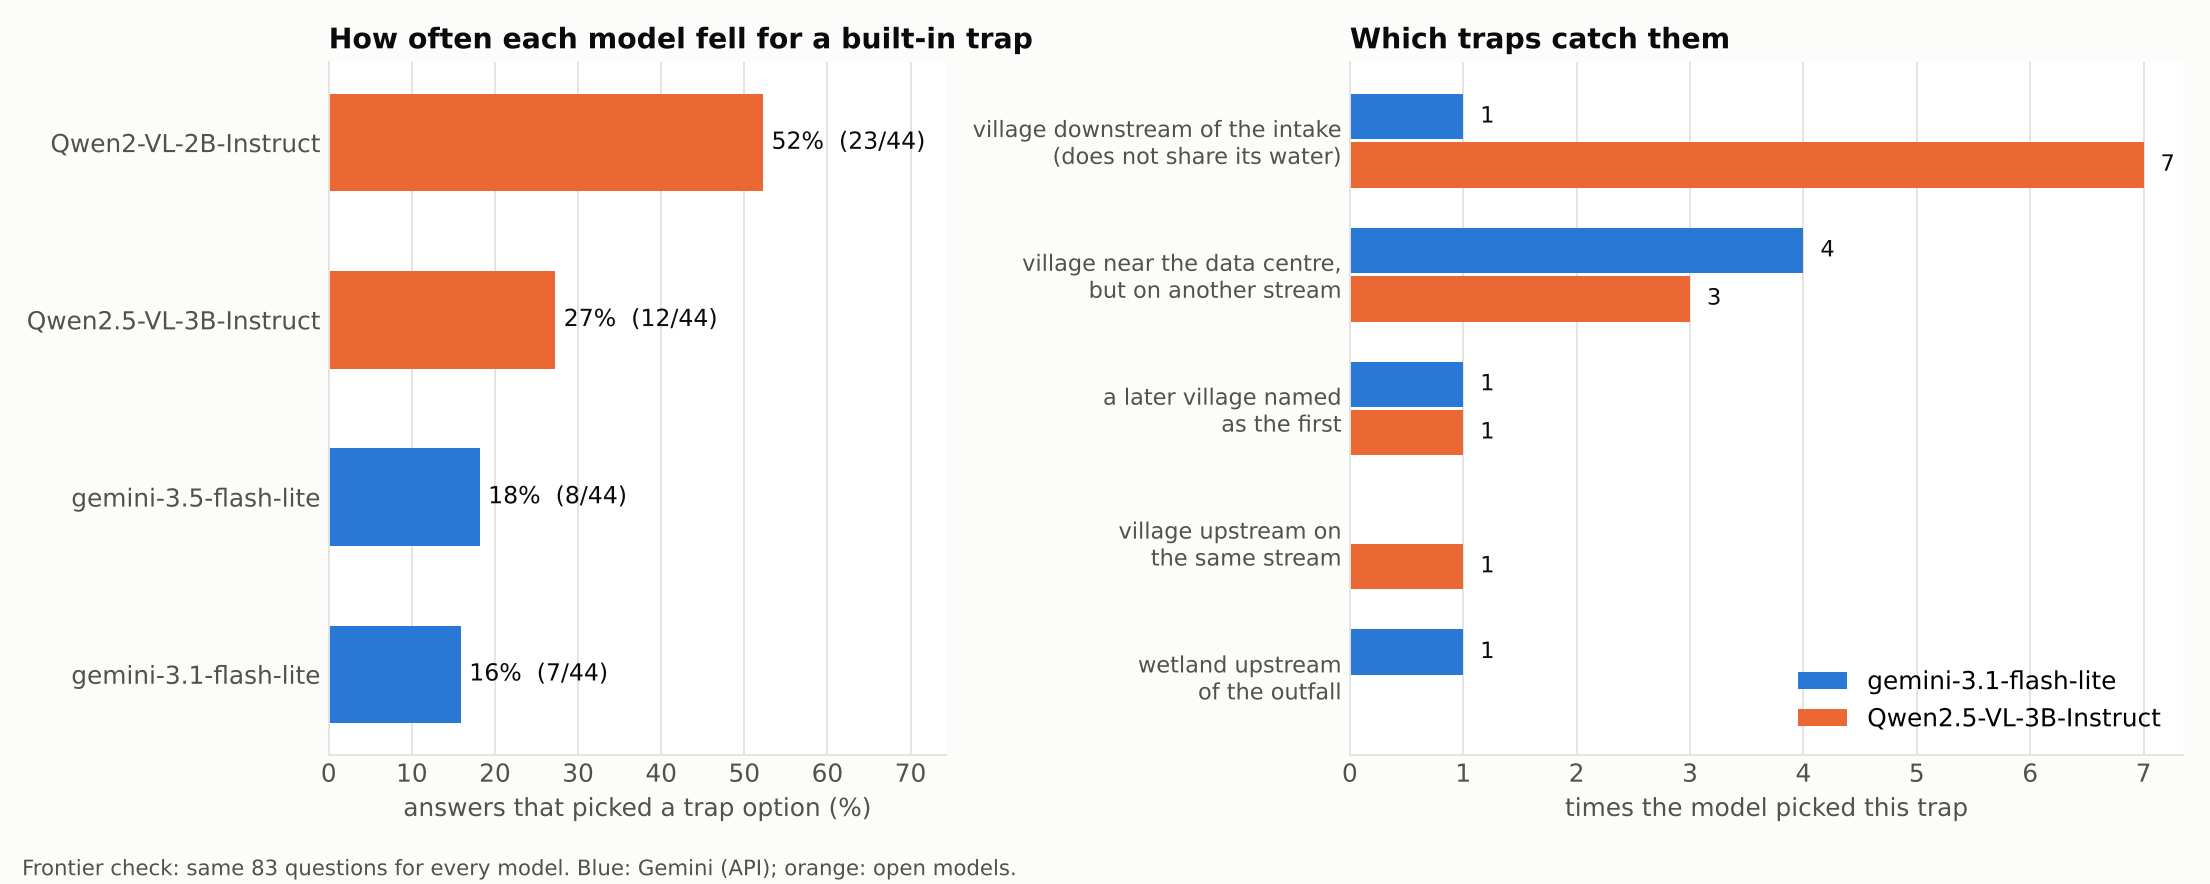

In [10]:
import urllib.request
from IPython.display import Markdown

RAW = "https://raw.githubusercontent.com/yugesh1111/THIRSTMAP/main/"
board = urllib.request.urlopen(RAW + "LEADERBOARD.md").read().decode()
display(Markdown(board.split("## Add your model")[0]))
display(Picture(data=urllib.request.urlopen(RAW + "docs/trap_chart.png").read(), width=720))

## Where next

- A full dataset: `thirstmap build --per-level 18 --out dataset --workers 4` (add `--real-per-location 9` for real terrain from
  Copernicus DEM and ESA WorldCover after `pip install rasterio`)
- Score your own model on the published evaluation set: see the repository's *Add your model* section
- Every validation check, the self-audit and the byte-for-byte rebuilds: [`docs/VALIDATION_REPORT.md`](https://github.com/yugesh1111/THIRSTMAP/blob/main/docs/VALIDATION_REPORT.md)